**I built a machine learning system that predicts a person's medical insurance cost based on information such as age, BMI, number of children, smoking status, gender, and region, and I also explored whether the predictions differed across demographic groups.**

**Import Liabraries**

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import warnings
warnings.filterwarnings('ignore')

**Load Dataset**
- To See complete Dataset Structure(rows,columns)

In [2]:
df = pd.read_csv('insurance.csv')
df.head()

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


**Data Information and shape and sizes**

In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1338 non-null   int64  
 1   sex       1338 non-null   object 
 2   bmi       1338 non-null   float64
 3   children  1338 non-null   int64  
 4   smoker    1338 non-null   object 
 5   region    1338 non-null   object 
 6   charges   1338 non-null   float64
dtypes: float64(2), int64(2), object(3)
memory usage: 73.3+ KB


In [4]:
df.describe()

,age,bmi,children,charges
count,1338.000000,1338.000000,1338.000000,1338.000000
mean,39.207025,30.663397,1.094918,13270.422265
std,14.049960,6.098187,1.205493,12110.011237
min,18.000000,15.960000,0.000000,1121.873900
25%,27.000000,26.296250,0.000000,4740.287150
50%,39.000000,30.400000,1.000000,9382.033000
75%,51.000000,34.693750,2.000000,16639.912515
max,64.000000,53.130000,5.000000,63770.428010


In [5]:
df.shape

(1338, 7)

**Data Preprocessing**  (Check Missing values)

In [6]:
df.isnull().sum()

age         0
sex         0
bmi         0
children    0
smoker      0
region      0
charges     0
dtype: int64

**Exploratory Data Analysis (EDA)**

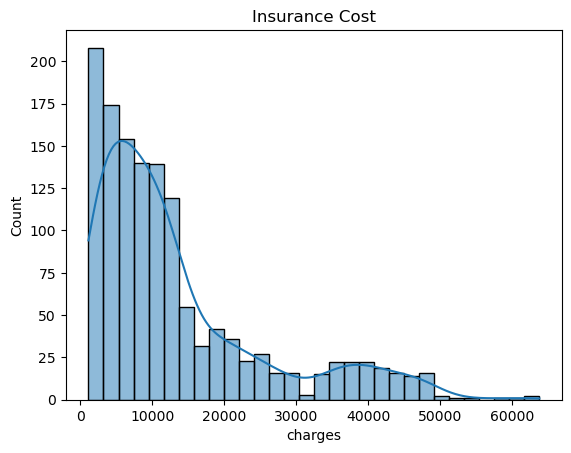

In [7]:
sns.histplot(df['charges'], kde=True) # To check data is skewed or not. if skewed whcih skewed? Right skewed or left skewed
plt.title('Insurance Cost')
plt.show()

**Smoking Vs Cost**

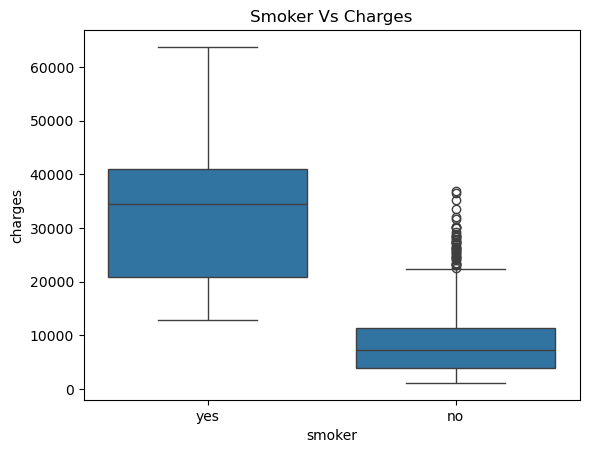

In [8]:
sns.boxplot(x='smoker',y='charges', data=df)
plt.title('Smoker Vs Charges')
plt.show()

In [9]:
df['sex'].value_counts()

sex
male      676
female    662
Name: count, dtype: int64

**Feature Encoding** is (Orderd &Unordered) (Categories Data to Numerical Data)
- using for Unordered, generally this means(One Hot encoding)
- ML Cannot Understand text categorical Data so using func(get_dummies) for multiple columns can change categories to numerical. <br>
Example:
- Male -> (1)
- Female-> (0)
- drop_first=True ?.. To avoid dummy variable trap. For example, you don't need a sex_female column if you have sex_male. If sex_male is False, the computer knows the person must be female

In [10]:
df = pd.get_dummies(df, drop_first=True)
df.head(3)

,age,bmi,children,charges,sex_male,smoker_yes,region_northwest,region_southeast,region_southwest
0,19,27.90,0,16884.9240,False,True,False,False,True
1,18,33.77,1,1725.5523,True,False,False,True,False
2,28,33.00,3,4449.4620,True,False,False,True,False


**Train Test Split**
- split data to avoid overfitting or predict data
- We split the data to evaluate the model on unseen data and ensure it generalizes well without overfitting to the training set.

In [11]:
X = df.drop('charges',axis=1)
y = df['charges']

In [12]:
from sklearn.model_selection import train_test_split
X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.2,random_state=42)

**Train Models**
- handles nonlinear relationships
- strong baseline model

**Random Forest Regressor**
- It builds hundreds of individual "Decision Trees" on different random slices of your data.
- The Result: Each tree gives a prediction, and the Random Forest takes the average of all those trees<br>

**XGBoost Regressor**
-  It also uses trees, but it builds them one by one. The first tree makes a guess. The second tree looks at where the first tree was wrong and focuses only on fixing those errors. The third tree fixes the errors of the second, and so on. (it is better than Random Forest)

In [13]:
from sklearn.ensemble import RandomForestRegressor
rf = RandomForestRegressor()
rf.fit(X_train, y_train)

RandomForestRegressor()

In [14]:
pip install xgboost

Note: you may need to restart the kernel to use updated packages.


**XGBoost**
- one of the best tabular models
- high accuracy

In [15]:
from xgboost import XGBRegressor
xgb = XGBRegressor()
xgb.fit(X_train, y_train)

XGBRegressor(base_score=None, booster=None, callbacks=None,
             colsample_bylevel=None, colsample_bynode=None,
             colsample_bytree=None, device=None, early_stopping_rounds=None,
             enable_categorical=False, eval_metric=None, feature_types=None,
             feature_weights=None, gamma=None, grow_policy=None,
             importance_type=None, interaction_constraints=None,
             learning_rate=None, max_bin=None, max_cat_threshold=None,
             max_cat_to_onehot=None, max_delta_step=None, max_depth=None,
             max_leaves=None, min_child_weight=None, missing=nan,
             monotone_constraints=None, multi_strategy=None, n_estimators=None,
             n_jobs=None, num_parallel_tree=None, ...)

**Model Evaluation** <br>
Why R²?
- It measures how well predictions match reality.
- if Score is 1; it is perfect, if 0.8 then it is very Good, else 0.5 it is weak

In [16]:
rf_pred = rf.predict(X_test)
xgb_pred = xgb.predict(X_test)
print('RF R2:\n',y_test,rf_pred)
print('\n XGB R2:\n',y_test,xgb_pred)

RF R2:
 764      9095.06825
887      5272.17580
890     29330.98315
1293     9301.89355
259     33750.29180
           ...     
109     47055.53210
575     12222.89830
535      6067.12675
543     63770.42801
846      9872.70100
Name: charges, Length: 268, dtype: float64 [ 9551.7220375   5177.6962272  28051.737493   10309.9707571
 34616.5071873   9341.4159908   2123.0976     14337.483078
  6482.2829127  11280.5509318  19557.3080328   7157.5402204
  4704.4990218  45861.6060832  48367.1855492  44862.4775702
 10312.6908776  42803.473168    8952.7409387  23682.8053156
  8042.2919199   8958.493118    1995.31880555  2376.3746873
 11672.1141062  11452.2630134  13527.6167291   6642.2578716
 11747.455971    5539.06670247  8054.2022238  11972.0039176
  3828.827617    5517.9721961   4357.1467828  10049.3303126
  2338.401873    7856.8109138  23913.2046385  39238.422043
  5768.8937643   3690.7198525  12351.536905   14929.8403117
  6508.1192384  14659.0055128  20946.9990255  11227.0342326
 41986.8057

In [ ]:
from sklearn.metrics import mean_absolute_error, r2_score

rf_mae = mean_absolute_error(y_test, rf_pred)  # Mean Absolute Error
rf_r2 = r2_score(y_test, rf_pred)
print(f"RF  -> MAE: {rf_mae:.2f}, R2: {rf_r2:.4f}")

In [ ]:
xgb_mae = mean_absolute_error(y_test, xgb_pred)
xgb_r2 = r2_score(y_test, xgb_pred)
print(f"RF  -> MAE: {rf_mae:.2f}, R2: {rf_r2:.4f}")
print(f"XGB -> MAE: {xgb_mae:.2f}, R2: {xgb_r2:.4f}")

**Fairness Analysis**
- we can check bias. Gender Bias
- checking if our model’s predictions are biased or unfair toward specific groups of people based on attributes like age, gender, or smoking status.

In [18]:
X_test['prediction'] = rf_pred
X_test['actual'] = y_test.values

In [19]:
male_avg = X_test[X_test['sex_male'] == 1]['prediction'].mean()
female_avg = X_test[X_test['sex_male'] == 0]['prediction'].mean()

In [20]:
male_avg,female_avg

(np.float64(14524.541270108399), np.float64(12540.94598576012))

In [21]:
pip install aif360

Note: you may need to restart the kernel to use updated packages.


**SHAP**<br>
This shows Feature importance<br>
- Below are columns belongs to (Features) (impact)
- smoker(Features) -> highest(impact)
- bmi    -> medium
- age    -> medium


In [22]:
pip install shap

Note: you may need to restart the kernel to use updated packages.


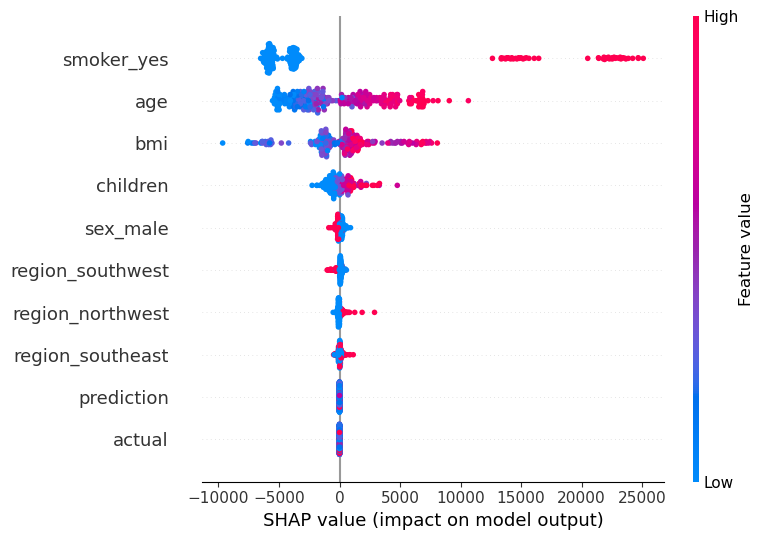

In [23]:
import shap
explainer = shap.TreeExplainer(rf)
shap_values = explainer.shap_values(X_test)
shap.summary_plot(shap_values,X_test)

**Save Model**
- we save the model for API usage:

In [24]:
import pickle
pickle.dump(rf, open("../model/model.pkl","wb"))

**FastAPI Prediction API**
- Using FastAPI

In [25]:
pip install fastapi

Note: you may need to restart the kernel to use updated packages.


In [26]:
import pickle
from fastapi import FastAPI

app = FastAPI()

model = pickle.load(open("../model/model.pkl", "rb"))

In [27]:
pip install fastapi uvicorn

Note: you may need to restart the kernel to use updated packages.


In [28]:
pip install python-multipart

Note: you may need to restart the kernel to use updated packages.


In [29]:
pip install mlflow

Note: you may need to restart the kernel to use updated packages.


In [30]:
import mlflow
from sklearn.metrics import r2_score

with mlflow.start_run():
    mlflow.log_metric("R2_score", r2_score(y_test, rf_pred))

2026/09/26 16:21:10 INFO mlflow.store.db.utils: Creating initial MLflow database tables...
2026/09/26 16:21:10 INFO mlflow.store.db.utils: Updating database tables
